C:\Users\saksham\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3497 - loss: 2.2266
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6104 - loss: 1.3143
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7017 - loss: 1.0048
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7583 - loss: 0.8200
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7983 - loss: 0.6903
Epoch 6/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8327 - loss: 0.5899
Epoch 7/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8571 - loss: 0.5090
Epoch 8/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8845 - loss: 0.4329
Epoch 9/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8997 - loss: 0.3753
Epoch 10/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9148 - loss: 0.3260
Epoch 11/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9329 - loss: 0.2744
Epoch 12/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

array([<Axes: >, <Axes: >], dtype=object)

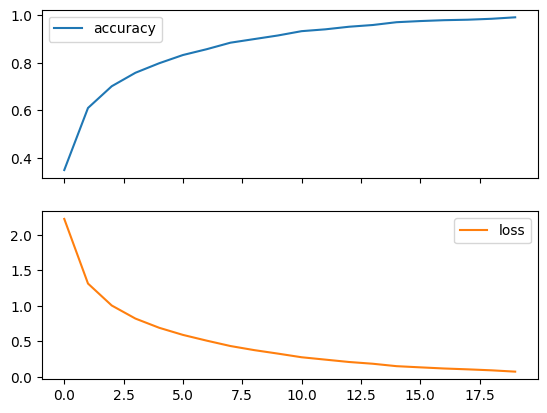

In [1]:

import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.preprocessing import LabelEncoder

# Load data
train = pd.read_csv("LP IV Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("LP IV Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

x_train = train.iloc[0:, 1:] / 255
x_test = test.iloc[0:, 1:] / 255

encoder = LabelEncoder()
y_train = encoder.fit_transform(train.iloc[0:, 0])
y_test = encoder.transform(test.iloc[0:, 0])

# Create model
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(24, activation='softmax')
])

# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train
history = model.fit(x_train, y_train, epochs=20)

# Evaluate
loss, accuracy = model.evaluate(x_test, y_test)
print("Accuracy:", accuracy * 100, "%")

# Plot
pd.DataFrame(history.history).plot(subplots=True)
